# TP3 · Paso 3 — Análisis de errores, curvas de aprendizaje y enfoque data-centered

Dejamos **fijo** el baseline del paso 2 (HistGradientBoosting ajustado, 28 variables originales) y estudiamos **qué tipo de errores comete y qué tienen en común** (clase 11, *error analysis*).

Para no usar el test, los errores se analizan sobre las **predicciones out-of-fold (OOF)** de la CV por grupos en train: cada reserva se predice con un modelo que no la vio (ni a sus duplicados).

In [1]:
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from sklearn.model_selection import cross_val_predict, learning_curve

import tp3_comun as C

X_train, y_train = C.cargar_split("train")
grupos = C.firma_duplicados(X_train)
base = joblib.load(C.RESULTADOS / "paso2_baseline.joblib")
modelo = base["modelo"]
print("Baseline:", base["nombre"])

proba = cross_val_predict(modelo, X_train, y_train, groups=grupos, cv=C.crear_cv("grupo"),
                          method="predict_proba", n_jobs=5)[:, 1]
pred = (proba >= 0.5).astype(int)
print(C.metricas(y_train, proba))

Baseline: HGB ajustado


{'bal_acc': 0.8523846933384637, 'roc_auc': 0.9389107356699775}


## 3.1 Análisis de errores

### Matriz de confusión global (OOF)

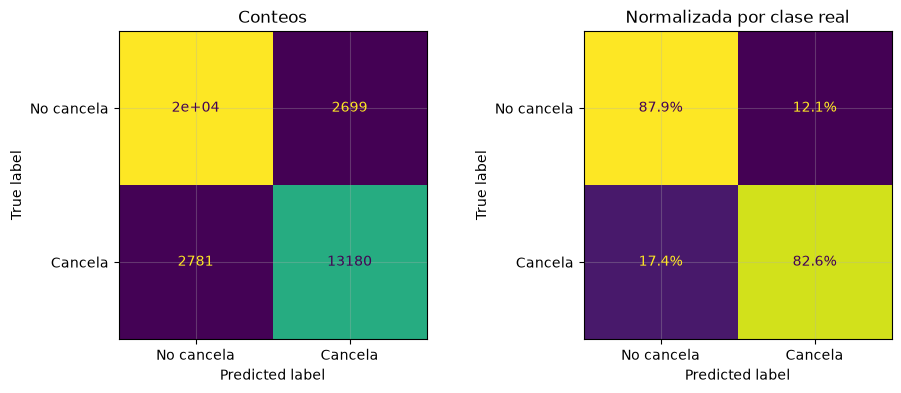

FP = 2,699 (reservas que se ejecutan pero predecimos cancelación)
FN = 2,781 (cancelaciones que no anticipamos)
TPR (recall cancel.) = 0.826 | TNR (especificidad) = 0.879


In [2]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(y_train, pred, ax=axes[0], display_labels=["No cancela", "Cancela"], colorbar=False)
ConfusionMatrixDisplay.from_predictions(y_train, pred, ax=axes[1], display_labels=["No cancela", "Cancela"],
                                        normalize="true", values_format=".1%", colorbar=False)
axes[0].set_title("Conteos"); axes[1].set_title("Normalizada por clase real")
C.guardar(fig, "08_confusion_baseline.png"); plt.show()
tn, fp, fn, tp = confusion_matrix(y_train, pred).ravel()
print(f"FP = {fp:,} (reservas que se ejecutan pero predecimos cancelación)")
print(f"FN = {fn:,} (cancelaciones que no anticipamos)")
print(f"TPR (recall cancel.) = {tp/(tp+fn):.3f} | TNR (especificidad) = {tn/(tn+fp):.3f}")

### Definición de cohortes / *tags*

Siguiendo la clase 11, elegimos los factores a analizar:
- Los que pide la consigna: **`client_type`**, **`service_tier`**, **`reserved_gpu_type`**.
- Tags adicionales surgidos del EDA: región (`PRT` vs. resto), `reservation_commitment`, GPU cambiada, anticipación de la reserva y **si la reserva es única o pertenece a un lote de duplicados**.

Para cada valor calculamos: tamaño, tasa real de cancelación, balanced accuracy, % de error, FP, FN y **qué porcentaje de todos los errores aporta** (cuánto mejoraría el total si arregláramos esa cohorte).

In [3]:
df_err = X_train.copy()
df_err["y"], df_err["pred"], df_err["proba"] = y_train.values, pred, proba
df_err["region"] = np.where(df_err["client_region"] == "PRT", "PRT", "otras")
df_err["gpu_cambiada"] = np.where(df_err["reserved_gpu_type"] != df_err["assigned_gpu_type"], "sí", "no")
df_err["anticipacion"] = pd.cut(df_err["hours_before_execution"], [-1, 24, 72, 168, 1e9],
                               labels=["≤1 día", "1-3 días", "3-7 días", ">7 días"]).astype(str)
tam = pd.Series(grupos).map(pd.Series(grupos).value_counts()).values
df_err["lote"] = np.where(tam == 1, "única", np.where(tam <= 5, "lote 2-5", "lote 6+"))

for col in C.COHORTES:
    print(f"\n=== {col} ===")
    display(C.tabla_cohorte(df_err, col).round(3))


=== client_type ===


,client_type,n,%_datos,tasa_cancel,bal_acc,error_%,FP,FN,%_de_errores
0,cloud_marketplace,18627,48.675,0.377,0.777,21.340,2151,1824,72.536
1,managed_account,8495,22.199,0.451,0.930,6.816,223,356,10.566
2,research_consortium,6414,16.761,0.664,0.936,5.379,208,137,6.296
3,independent_client,2898,7.573,0.158,0.639,13.423,72,317,7.099
4,enterprise_client,1464,3.826,0.238,0.839,9.426,38,100,2.518
5,sponsored_project,249,0.651,0.104,0.529,11.245,4,24,0.511
6,high_priority_partner,121,0.316,0.198,0.505,21.488,3,23,0.474



=== service_tier ===


,service_tier,n,%_datos,tasa_cancel,bal_acc,error_%,FP,FN,%_de_errores
0,standard,30096,78.645,0.430,0.867,12.975,1895,2010,71.259
1,basic,5059,13.220,0.381,0.775,21.704,603,495,20.036
2,priority,3105,8.114,0.348,0.823,15.362,201,276,8.704
3,enterprise,8,0.021,0.625,1.000,0.000,0,0,0.000



=== reserved_gpu_type ===


,reserved_gpu_type,n,%_datos,tasa_cancel,bal_acc,error_%,FP,FN,%_de_errores
0,GPU_T1,30128,78.729,0.436,0.870,12.756,1831,2012,70.128
1,GPU_T4,5760,15.052,0.346,0.783,20.312,645,525,21.350
2,GPU_T6,868,2.268,0.407,0.791,21.313,120,65,3.376
3,GPU_T5,732,1.913,0.327,0.730,22.268,66,97,2.974
4,GPU_T2,549,1.435,0.328,0.794,16.393,31,59,1.642
5,GPU_T7,218,0.570,0.261,0.841,10.092,6,16,0.401
6,GPU_T3,7,0.018,0.571,0.875,14.286,0,1,0.018
7,GPU_T12,6,0.016,1.000,NaN,100.000,0,6,0.109


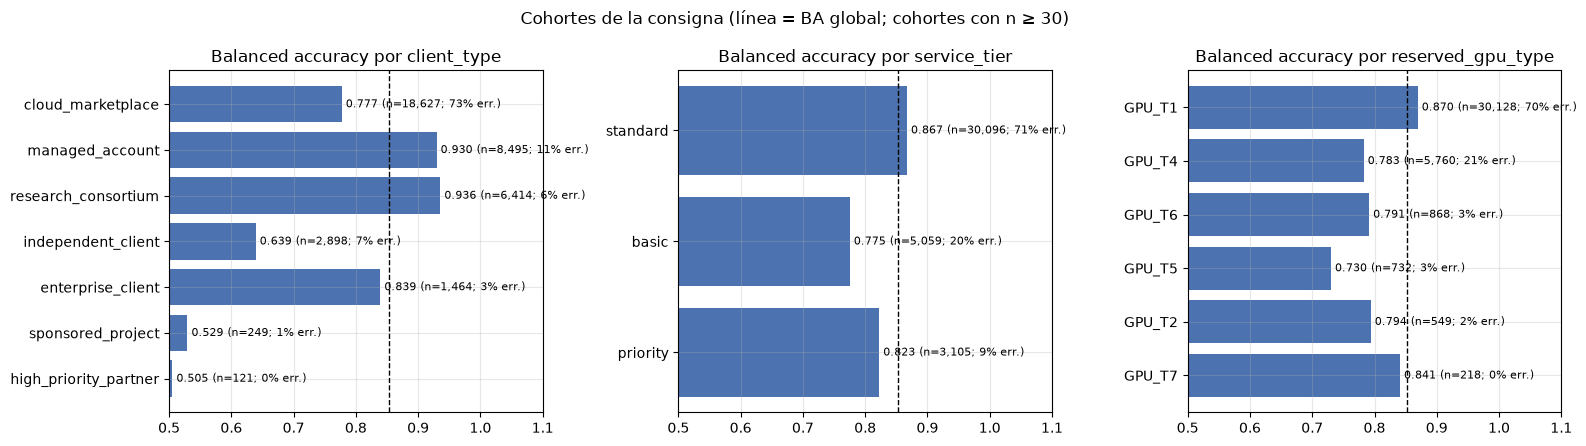

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col in zip(axes, C.COHORTES):
    t = C.tabla_cohorte(df_err, col)
    t = t[t["n"] >= 30]
    ax.barh(t[col].astype(str)[::-1], t["bal_acc"][::-1], color="#4C72B0")
    for i, (b, n, e) in enumerate(zip(t["bal_acc"][::-1], t["n"][::-1], t["%_de_errores"][::-1])):
        ax.text(b, i, f" {b:.3f} (n={n:,}; {e:.0f}% err.)", va="center", fontsize=8)
    ax.axvline(C.metricas(y_train, proba)["bal_acc"], c="k", ls="--", lw=1)
    ax.set_xlim(0.5, 1.1); ax.set_title(f"Balanced accuracy por {col}")
fig.suptitle("Cohortes de la consigna (línea = BA global; cohortes con n ≥ 30)"); fig.tight_layout()
C.guardar(fig, "09_cohortes_error.png"); plt.show()

### Tags adicionales

In [5]:
for col in ["region", "reservation_commitment", "gpu_cambiada", "anticipacion", "lote"]:
    print(f"\n=== {col} ===")
    display(C.tabla_cohorte(df_err, col).round(3))


=== region ===


,region,n,%_datos,tasa_cancel,bal_acc,error_%,FP,FN,%_de_errores
0,otras,23331,60.967,0.268,0.800,15.889,1899,1808,67.646
1,PRT,14937,39.033,0.650,0.873,11.870,800,973,32.354



=== reservation_commitment ===


,reservation_commitment,n,%_datos,tasa_cancel,bal_acc,error_%,FP,FN,%_de_errores
0,no_commitment,31921,83.414,0.302,0.795,17.142,2693,2779,99.854
1,locked_allocation,6339,16.565,0.997,0.812,0.095,6,0,0.109
2,flexible_commitment,8,0.021,0.625,0.800,25.000,0,2,0.036



=== gpu_cambiada ===


,gpu_cambiada,n,%_datos,tasa_cancel,bal_acc,error_%,FP,FN,%_de_errores
0,no,34817,90.982,0.452,0.847,15.171,2638,2644,96.387
1,sí,3451,9.018,0.060,0.660,5.737,61,137,3.613



=== anticipacion ===


,anticipacion,n,%_datos,tasa_cancel,bal_acc,error_%,FP,FN,%_de_errores
0,3-7 días,10132,26.476,0.468,0.832,16.927,981,734,31.296
1,≤1 día,9817,25.653,0.197,0.747,13.212,423,874,23.668
2,1-3 días,9442,24.673,0.415,0.826,16.829,787,802,28.996
3,>7 días,8877,23.197,0.605,0.893,9.902,508,371,16.040



=== lote ===


,lote,n,%_datos,tasa_cancel,bal_acc,error_%,FP,FN,%_de_errores
0,única,22714,59.355,0.284,0.785,17.654,2042,1968,73.175
1,lote 6+,10050,26.262,0.746,0.931,5.104,265,248,9.361
2,lote 2-5,5504,14.383,0.366,0.803,17.387,392,565,17.464


### Tabla de impacto (estilo clase 11)

En datos tabulares el *Human Level Performance* no es una buena referencia (clase 11). Como referencia de "rendimiento alcanzable" usamos la **mejor cohorte grande** (n > 1000) y estimamos la **contribución de cada cohorte al gap** como `gap × % de datos`.

In [6]:
filas = []
for col in ["client_type", "service_tier", "reserved_gpu_type", "region", "anticipacion", "lote"]:
    t = C.tabla_cohorte(df_err, col)
    for _, r in t[t["n"] >= 300].iterrows():
        filas.append({"tag": f"{col} = {r[col]}", "n": r["n"], "%_datos": r["%_datos"],
                      "bal_acc": r["bal_acc"], "error_%": r["error_%"], "%_de_errores": r["%_de_errores"]})
imp = pd.DataFrame(filas)
ref = imp.loc[imp["n"] > 1000, "bal_acc"].max()
imp["gap_vs_mejor"] = ref - imp["bal_acc"]
imp["contrib_gap"] = imp["gap_vs_mejor"] * imp["%_datos"] / 100
print(f"Referencia (mejor cohorte grande): BA = {ref:.3f}")
imp.sort_values("contrib_gap", ascending=False).head(12).round(3)

Referencia (mejor cohorte grande): BA = 0.936


,tag,n,%_datos,bal_acc,error_%,%_de_errores,gap_vs_mejor,contrib_gap
19,lote = única,22714,59.355,0.785,17.654,73.175,0.151,0.090
13,region = otras,23331,60.967,0.800,15.889,67.646,0.136,0.083
0,client_type = cloud_marketplace,18627,48.675,0.777,21.340,72.536,0.158,0.077
5,service_tier = standard,30096,78.645,0.867,12.975,71.259,0.069,0.054
8,reserved_gpu_type = GPU_T1,30128,78.729,0.870,12.756,70.128,0.066,0.052
16,anticipacion = ≤1 día,9817,25.653,0.747,13.212,23.668,0.189,0.048
15,anticipacion = 3-7 días,10132,26.476,0.832,16.927,31.296,0.104,0.028
17,anticipacion = 1-3 días,9442,24.673,0.826,16.829,28.996,0.109,0.027
14,region = PRT,14937,39.033,0.873,11.870,32.354,0.062,0.024
9,reserved_gpu_type = GPU_T4,5760,15.052,0.783,20.312,21.350,0.153,0.023


### Falsos positivos y falsos negativos: ¿cómo son?

In [7]:
Xf = C.agregar_features(X_train)
Xf["tipo"] = np.select([(pred == 1) & (y_train == 1), (pred == 0) & (y_train == 0),
                        (pred == 1) & (y_train == 0), (pred == 0) & (y_train == 1)], ["TP", "TN", "FP", "FN"], default="?")
cols = ["hours_before_execution", "total_gpu_hours", "estimated_cost_per_hour", "special_resource_requests",
        "resource_modifications", "previous_job_cancellations", "gpu_changed", "has_agent"]
resumen = Xf.groupby("tipo")[cols].mean().loc[["TP", "FN", "TN", "FP"]].T
for t in ["TP", "FN", "TN", "FP"]:
    resumen.loc["% PRT (región)", t] = (Xf.loc[Xf["tipo"] == t, "client_region"] == "PRT").mean()
    resumen.loc["% locked_allocation", t] = (Xf.loc[Xf["tipo"] == t, "reservation_commitment"] == "locked_allocation").mean()
    resumen.loc["% cloud_marketplace", t] = (Xf.loc[Xf["tipo"] == t, "client_type"] == "cloud_marketplace").mean()
    resumen.loc["% reserva única (sin lote)", t] = (df_err.loc[Xf["tipo"] == t, "lote"] == "única").mean()
resumen.astype(float).round(3)

tipo,TP,FN,TN,FP
hours_before_execution,159.547,76.171,79.133,100.191
total_gpu_hours,24.667,23.692,23.107,25.856
estimated_cost_per_hour,5.123,5.629,5.225,5.820
special_resource_requests,0.153,0.881,0.768,0.515
resource_modifications,0.052,0.222,0.285,0.107
previous_job_cancellations,0.192,0.008,0.021,0.009
gpu_changed,0.005,0.049,0.162,0.023
has_agent,0.932,0.908,0.866,0.969
% PRT (región),0.663,0.350,0.226,0.296
% locked_allocation,0.480,0.000,0.001,0.002


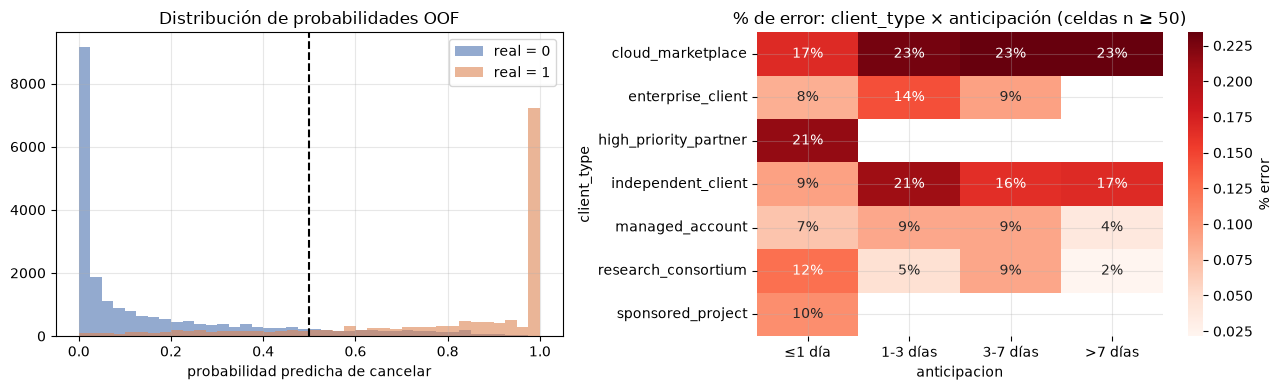

Reservas con probabilidad 'dudosa' (0.35-0.65): 13.2% de los datos, concentran el 39% de los errores


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(proba[y_train == 0], bins=40, alpha=0.6, label="real = 0", color="#4C72B0")
axes[0].hist(proba[y_train == 1], bins=40, alpha=0.6, label="real = 1", color="#DD8452")
axes[0].axvline(0.5, c="k", ls="--"); axes[0].set_xlabel("probabilidad predicha de cancelar"); axes[0].legend()
axes[0].set_title("Distribución de probabilidades OOF")
err = (df_err["y"] != df_err["pred"]).astype(int)
mapa = err.groupby([df_err["client_type"], df_err["anticipacion"]]).mean().unstack()
cnt = err.groupby([df_err["client_type"], df_err["anticipacion"]]).size().unstack()
mapa = mapa.where(cnt >= 50)[["≤1 día", "1-3 días", "3-7 días", ">7 días"]]
sns.heatmap(mapa, annot=True, fmt=".0%", cmap="Reds", ax=axes[1], cbar_kws={"label": "% error"})
axes[1].set_title("% de error: client_type × anticipación (celdas n ≥ 50)")
fig.tight_layout(); C.guardar(fig, "10_regiones_problematicas.png"); plt.show()
zona = (proba > 0.35) & (proba < 0.65)
print(f"Reservas con probabilidad 'dudosa' (0.35-0.65): {zona.mean():.1%} de los datos, "
      f"concentran el {(zona & (pred != y_train)).sum() / (pred != y_train).sum():.0%} de los errores")

### Conclusiones del análisis de errores

- **Global:** los errores están **equilibrados** entre FP (2 699) y FN (2 781). TPR = 0.83 y TNR = 0.88, así que no hay un sesgo fuerte hacia una clase y el umbral de 0.5 (con `class_weight="balanced"`) es razonable.
- **`client_type = cloud_marketplace` es la región problemática:**
  - Es el **49 %** de los datos pero aporta el **73 % de todos los errores**.
  - Su balanced accuracy es **0.777**, contra 0.93 de `managed_account` y `research_consortium`, con un 21 % de error.
  - Concentra además el **80 % de los FP**.
- **Cohortes chicas con mal rendimiento:** `independent_client` (0.64), `sponsored_project` (0.53) y `high_priority_partner` (0.51). Cancelan poco (10-20 %) y el modelo casi nunca acierta sus cancelaciones, pero entre las tres suman sólo el 8 % de los errores.
- **`service_tier` y `reserved_gpu_type`:** `basic` (0.775) y `GPU_T4` (0.783) están por debajo de la media. Buena parte se explica porque se solapan con `cloud_marketplace`. `enterprise`, `GPU_T3` y `GPU_T12` tienen < 10 filas y sus métricas no son fiables.
- **Reservas únicas vs. lotes:** las reservas que **no se repiten** (59 % de los datos) tienen BA 0.785 y aportan el **73 % de los errores**. Los lotes de 6+ copias se predicen casi perfecto (0.93).
- **`locked_allocation` está resuelto** (0.1 % de error). Prácticamente **todos los errores (99.9 %)** están en `no_commitment`.
- **Anticipación:** las reservas de último momento (≤ 1 día) son las peor predichas (BA 0.747). Hay pocas cancelaciones en ese grupo y el modelo las confunde.
- **Cómo son los errores:**
  - Los **FN** (cancelaciones no previstas) parecen reservas "comprometidas": poca anticipación (76 h vs. 160 h de los TP), muchas `special_resource_requests` (0.88 vs. 0.15), casi nunca `locked_allocation` y fuera de PRT. **Con estas variables son indistinguibles de un TN.**
  - Los **FP** tienen más anticipación y son mayoritariamente `cloud_marketplace` (80 %).
- **Incertidumbre:** el 13 % de las reservas reciben una probabilidad "dudosa" (0.35-0.65) y ahí está el **39 % de los errores**.

## 3.2 Curvas de aprendizaje

Entrenamos el baseline con fracciones crecientes de train (10 % → 100 %) y medimos train y validación con la misma CV por grupos.

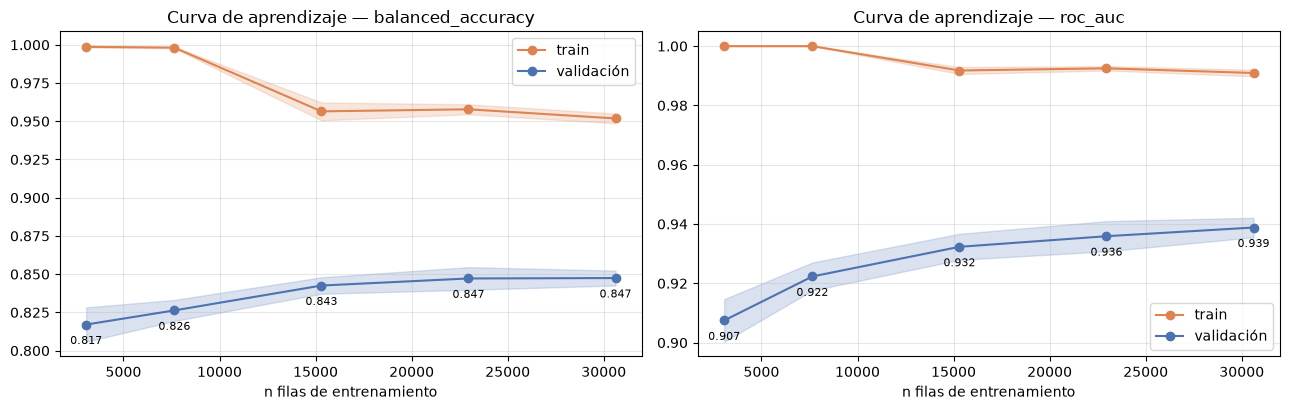

,n_train,train_BA,val_BA,brecha
0,3061,0.9987,0.8171,0.1816
1,7653,0.9981,0.8263,0.1718
2,15306,0.9565,0.8426,0.1139
3,22959,0.9578,0.8472,0.1106
4,30613,0.9518,0.8475,0.1044


In [9]:
tamanos = [0.1, 0.25, 0.5, 0.75, 1.0]
curvas = {}
for metrica in ["balanced_accuracy", "roc_auc"]:
    n, tr, va = learning_curve(modelo, X_train, y_train, groups=grupos, cv=C.crear_cv("grupo"),
                               train_sizes=tamanos, scoring=metrica, n_jobs=5, shuffle=True,
                               random_state=C.RANDOM_STATE)
    curvas[metrica] = (n, tr, va)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, (metrica, (n, tr, va)) in zip(axes, curvas.items()):
    for s, lab, col in [(tr, "train", "#DD8452"), (va, "validación", "#4C72B0")]:
        ax.plot(n, s.mean(1), "o-", c=col, label=lab)
        ax.fill_between(n, s.mean(1) - s.std(1), s.mean(1) + s.std(1), color=col, alpha=0.2)
    for x, v in zip(n, va.mean(1)):
        ax.annotate(f"{v:.3f}", (x, v), textcoords="offset points", xytext=(0, -14), ha="center", fontsize=8)
    ax.set_xlabel("n filas de entrenamiento"); ax.set_title(f"Curva de aprendizaje — {metrica}"); ax.legend()
fig.tight_layout(); C.guardar(fig, "11_curvas_aprendizaje.png"); plt.show()
n, tr, va = curvas["balanced_accuracy"]
pd.DataFrame({"n_train": n, "train_BA": tr.mean(1), "val_BA": va.mean(1), "brecha": tr.mean(1) - va.mean(1)}).round(4)

**Diagnóstico (clase 11):**
- **El modelo tiene capacidad suficiente:** la BA de train es ~0.95, así que no hay *high bias* en el sentido de no poder aprender train.
- **Hay *high variance*:** queda una brecha train–validación de ~0.10.
- **La validación se estanca:** pasa de 0.817 a 0.843 hasta el 50 % de los datos, y del 50 % al 100 % (de 15 000 a 30 000 filas) sólo sube **+0.005**.

**¿Limitado por el modelo o por los datos?**
- Por los **datos**, en el sentido de la **información disponible en X**, no por la cantidad de filas.
- Duplicar el dataset con reservas **del mismo tipo** daría, extrapolando la curva, menos de 1 punto. **Conseguir más filas iguales no es la palanca principal.**
- Lo que limita es que, para buena parte de las reservas de `cloud_marketplace`, las 28 variables no permiten separar quién cancela. Coincide con el análisis de FN: hay reservas idénticas en X con resultados distintos.
- **Palancas útiles:**
  - **Mejor representación:** features nuevas e información adicional (adquisición de datos, 3.4).
  - **Reducción de varianza:** promediar modelos (ensembles) y regularizar.

## 3.3 Estrategia data-centered: cohorte prioritaria

**Cohorte elegida: `client_type = cloud_marketplace`** (y dentro de ella, las reservas únicas, `no_commitment`).

| Criterio (clase 11) | Valor |
|---|---|
| **Frecuencia** | 49 % de las reservas, el segmento más grande |
| **Margen de mejora** | BA 0.777 vs. 0.93 de las otras cohortes grandes (gap ≈ 0.16) |
| **Peso en el error total** | 73 % de los errores y 80 % de los FP |
| **Impacto operativo** | Es el canal "marketplace": reservas de clientes anónimos/ocasionales. Un FN deja GPUs reservadas sin uso (capacidad ociosa que no se re-vende); un FP lleva a sobre-reservar y a rechazar trabajos que sí iban a ejecutarse. Por volumen, es donde más capacidad se pierde. |

**Posibles causas del mal rendimiento:**
1. **Heterogeneidad:** el marketplace agrupa clientes muy distintos (regiones, agentes, canales), con una tasa de cancelación intermedia (38 %), lo que deja muchas reservas en la zona de incertidumbre.
2. **Falta de historial:** casi todos sus clientes son nuevos (`returning_client` ≈ 0 y sin cancelaciones previas). Justamente la información de comportamiento pasado, que es la más predictiva, no existe para ellos.
3. **Información de lote/agente sin explotar:** gran parte de las cancelaciones vienen en lotes (mismo agente, misma fecha). El modelo baseline usa `orchestration_agent_id` como número, sin orden real.
4. **Ruido irreducible:** hay reservas con las mismas 28 variables y resultado distinto.

**Siguientes pasos (se implementan en el notebook 04):**
- **Feature engineering orientado a la cohorte:** ids de agente/organización como categorías, costo total, calendario, ratio de cancelaciones previas, indicadores de faltantes.
- **Ponderación de ejemplos:** reducir el peso de los lotes muy repetidos para que el modelo no "gaste" capacidad en ellos (ya los predice bien) y aprenda más de las reservas únicas, donde están los errores.
- **Reducir varianza:** ensembles (votación RF + HGB) y búsqueda de hiperparámetros.
- **Ajuste del umbral** con predicciones OOF, para maximizar balanced accuracy.
- Medir siempre el impacto **global y en `cloud_marketplace`**.

## 3.4 Adquisición de datos

Datos adicionales que incorporaríamos, priorizando la cohorte `cloud_marketplace`:

1. **Historial agregado por organización/agente** (no sólo por cliente): tasa de cancelación pasada del agente de orquestación y de la organización, número de reservas activas y tiempo desde la última cancelación. El análisis de FN muestra que el historial previo es lo que más separa clases, y los clientes del marketplace no lo tienen a nivel individual.
2. **Timestamp exacto de creación y señales de "lote":** cuántas reservas hizo el mismo agente o cliente en la misma sesión. Distinguiría reservas especulativas masivas (que se cancelan en bloque) de reservas individuales.
3. **Señales de disponibilidad y precio del mercado al reservar:** ocupación del clúster, precio spot y si hubo una alternativa más barata después. Un cliente de marketplace cancela cuando encuentra algo mejor, y eso hoy no está en X.
4. **Interacción con la reserva:** si el cliente subió datos o imágenes de contenedor, o configuró el entorno. Son señales de compromiso real, equivalentes a `special_resource_requests` pero más ricas.
5. **Más ejemplos etiquetados de las cohortes chicas** (`independent_client`, `sponsored_project`, `high_priority_partner`): tienen BA de 0.5-0.64 con pocos cientos de filas. Ahí sí, más filas del mismo tipo ayudarían.

**¿Por qué esperamos mejora?** La curva de aprendizaje indica que más filas del mismo tipo aportan poco, mientras que el análisis de errores muestra FN indistinguibles con las variables actuales. Lo que falta es **información nueva en X** (nuevas columnas), que es la forma de atacar el error que hoy parece "irreducible".

In [10]:
joblib.dump({"proba_oof": proba, "pred_oof": pred, "df_err": df_err, "curvas": curvas},
            C.RESULTADOS / "paso3_errores.joblib")

['resultados\\paso3_errores.joblib']